In [1]:
import yt
import unyt
from unyt import unyt_quantity, unyt_array, km, s, Mpc, kg, m, Msun, kpc
from unyt import Gyr, Mpc, km, s
from unyt.physical_constants import G as G_unyt, kboltz, mp as mp_unyt  # G, k_B, m_p

import numpy as np
import matplotlib.pyplot as plt
import caesar
import pynbody as pnb
import pynbody.units as u
import pynbody.array as pna

import dill
import os
from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units, G
#from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units,

code = 'Simba'

target_halo = 284
snap_file = '/scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_284/snap_halo_284_151.hdf5'

# ADD CAESAR FILEPATH HERE TOO

snap = yt.load(snap_file)#, unit_system='cgs')
s = pnb.load(snap_file)

id_filepath = "/home/b/babul/stlock/entropy_profiles/finished/ids_formatted.txt" # containing halo data/ids


yt : [INFO     ] 2025-03-26 20:53:41,079 ComovingIntegrationOn does not exist, falling back to OmegaLambda
yt : [INFO     ] 2025-03-26 20:53:41,093 Calculating time from 1.000e+00 to be 4.375e+17 seconds
yt : [INFO     ] 2025-03-26 20:53:41,094 Assuming length units are in kpc/h (comoving)
yt : [INFO     ] 2025-03-26 20:53:41,182 Parameters: current_time              = 4.3748565942961094e+17 s
yt : [INFO     ] 2025-03-26 20:53:41,183 Parameters: domain_dimensions         = [1 1 1]
yt : [INFO     ] 2025-03-26 20:53:41,183 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2025-03-26 20:53:41,184 Parameters: domain_right_edge         = [200000. 200000. 200000.]
yt : [INFO     ] 2025-03-26 20:53:41,184 Parameters: cosmological_simulation   = True
yt : [INFO     ] 2025-03-26 20:53:41,185 Parameters: current_redshift          = 4.440892098500626e-16
yt : [INFO     ] 2025-03-26 20:53:41,185 Parameters: omega_lambda              = 0.7
yt : [INFO     ] 2025-03-26 20:53:41,185 

In [2]:
# MATCH BY MASS AND CONTAMINATION

# visualize_sims_yt

# find halo with mass closest to mass we want (around 13), check contamination and if its good/low, use it

In [3]:
## Metal indices
if code.lower() == 'simba':
    # Simba
    metals_idx = {'Z':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    metals_idx_xigrm = {'H':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    elems = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
elif code.lower() == 'simba-c':
    # Simba-C
    metals_idx = {'Z':0, 'H':1, 'He': 2, 'Li': 3, 'Be': 4, 'B': 5, 'C': 6, 'N': 7, 'O': 8, 'F': 9, 'Ne': 10, 'Na': 11, 'Mg': 12, 'Al':13,
                  'Si': 14, 'P': 15, 'S': 16, 'Cl': 17, 'Ar': 18, 'K': 19,'Ca': 20, 'Sc': 21, 'Ti': 22, 'V': 23, 'Cr': 24,
                  'Mn': 25, 'Fe': 26, 'Co': 27, 'Ni': 28, 'Cu': 29, 'Zn': 30}
    metals_idx_xigrm = {'H':0, 'He': 1, 'Li': 2, 'Be': 3, 'B': 4, 'C': 5, 'N': 6, 'O': 7, 'F': 8, 'Ne': 9, 'Na': 10, 'Mg': 11, 
                        'Al':12, 'Si': 13, 'P': 14, 'S': 15, 'Cl': 16, 'Ar': 17, 'K': 18,'Ca': 19, 'Sc': 20, 'Ti': 21, 'V': 22, 'Cr': 23,
                      'Mn': 24, 'Fe': 25, 'Co': 26, 'Ni': 27, 'Cu': 28, 'Zn': 29}
    elems=['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si',
           'P', 'S', 'Cl', 'Ar', 'K','Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']#, 'Ga', 'Ge']\n",
else:
    raise SystemExit('Code is not Simba or Simba-C')


In [4]:
# Get data, and some functions

data = snap.all_data()

def gas_entropy(field, data):
    return data["gas", "kT"] * data["gas", "El_number_density"] ** (-2.0/3.0)

def gas_entropy2(field, data):
    return data["gas", "kT"] * data["PartType0", "El_number_density"] ** (-2.0/3.0)

snap.add_field(
    ("gas", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy,
    sampling_type="cell",
)

snap.add_field(
    ("PartType0", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy2,
    sampling_type="particle",
    force_override=True
)

gas_entropy = data['gas', 'entropy']

def get_coordinates_by_id(id_filepath, target_id):
    with open(id_filepath, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 6:
                continue  # skip malformed lines
            
            try:
                obj_id = int(parts[2])
                if obj_id == target_id:
                    # parts[4] contains the coordinate string: (x,y,z)
                    coord_str = parts[4].strip('()')
                    x, y, z = map(float, coord_str.split(','))
                    return (x, y, z)
            except (ValueError, IndexError):
                continue  # skip malformed lines
    
    return None  # if ID not found



yt : [INFO     ] 2025-03-26 19:26:01,276 Allocating for 2.164e+08 particles
Loading particle index: 100%|██████████| 402/402 [00:00<00:00, 4157.29it/s]
/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/unyt/array.py:1949: RuntimeWarning: invalid value encountered in power
  out_arr = func(
/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/unyt/array.py:1949: RuntimeWarning: divide by zero encountered in power
  out_arr = func(


In [5]:
coords = get_coordinates_by_id(id_filepath, target_halo)
halo_center = unyt_array(coords, 'Mpc')
halo_center/=1000
print(halo_center)

[135.855266 101.053422  79.368945] Mpc


# Caesar (for finding correct halo by ID)

In [6]:
# obj = caesar.load('/scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_2919/Groups/Caesar_halo_2919_151.hdf5')
obj = caesar.load('/scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_284/Groups/Caesar_halo_284_151.hdf5')
halo_data = obj.halos

# Let’s say the ID of interest is halo_id
most_massive = halo_data[0]
for halo in halo_data:
    if halo.masses['stellar'] > most_massive.masses['stellar']:
        most_massive = halo

mass_min = 12.8
mass_max = 13.2

halos_in_range = [
    halo for halo in obj.halos
    if halo.masses['total'] > 0 and mass_min <= np.log10(halo.masses['total']) <= mass_max
    ]

yt : [INFO     ] 2025-03-26 19:28:32,367 Opening /scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_284/Groups/Caesar_halo_284_151.hdf5


yt : [INFO     ] 2025-03-26 19:28:32,750 Found 37286 halos
yt : [INFO     ] 2025-03-26 19:28:32,781 Found 3107 galaxies


In [17]:
for halo in halos_in_range:
    print("ID: ", halo.GroupID, ", Mass: ", np.log10(halo.masses['total']), ", Contamination: ", halo.contamination)

target_halo_id = 6

halo_center = halo_data[target_halo_id].minpotpos
halo_center = halo_center.in_units('Mpc')
print(halo_center)

ID:  6 , Mass:  13.12614930200153 , Contamination:  0.0
ID:  7 , Mass:  13.106213184075472 , Contamination:  0.655879538433657
ID:  8 , Mass:  13.047807220424863 , Contamination:  0.001420271123125555
ID:  9 , Mass:  13.030545758625177 , Contamination:  0.0017926625502849122
ID:  10 , Mass:  13.022419611343953 , Contamination:  1.4493008021595428
ID:  11 , Mass:  12.959306224914489 , Contamination:  1.1793872073997012
ID:  12 , Mass:  12.93129268482408 , Contamination:  0.0009321195724833122
ID:  13 , Mass:  12.852796564594607 , Contamination:  3.032355993591733
ID:  14 , Mass:  12.839003118606467 , Contamination:  0.0
[153.97954 140.3582  144.19186] Mpc


# Get Center of Gas Particles

In [7]:
# get center of gas particles 
gas_pos = data['gas', 'particle_position']

gas_pos_min = np.min(gas_pos, axis=0)
gas_pos_min.in_units('Mpc')

gas_pos_max = np.max(gas_pos, axis=0)
gas_pos_max.in_units('Mpc')

gas_zoom_centre = (gas_pos_min + gas_pos_max)/2.
gas_zoom_centre.in_units('Mpc')

gas_zoom_lengths = (gas_pos_max - gas_pos_min)/2.
gas_zoom_radius = np.mean(gas_zoom_lengths)
# gas_zoom_lengths.in_units('Mpc')
gas_zoom_radius.in_units('Mpc')

unyt_quantity(35.65045094, 'Mpc')

# Get minimum potential of gas particles

In [8]:
gas_pot = data['PartType0', 'Potential']
min_pot = np.min(gas_pot)
min_gas_pot_idx = np.argmin(gas_pot)
gas_pot[min_gas_pot_idx]
min_gas_pot_pos = data['gas', 'particle_position'][min_gas_pot_idx]
min_gas_pot_pos.in_units('Mpc')

max_gas_pot_idx = np.argmax(gas_pot)
max_gas_pot_pos = data['gas', 'position'][max_gas_pot_idx]
max_gas_pot_pos.in_units('Mpc')

min_pot_idx = np.argmin(data['all', 'Potential'])
min_pot_pos = data['all', 'particle_position'][min_pot_idx]
min_pot_pos.in_units('Mpc')

max_pot_idx = np.argmax(data['all', 'Potential'])
max_pot_pos = data['all', 'particle_position'][max_pot_idx]
max_pot_pos.in_units('Mpc')

unyt_array([ 81.02477597,   8.40057014, 239.7743796 ], 'Mpc')

# Get position of most massive black hole

In [9]:
# index
most_massive_bh_index = np.argmax(data['PartType5', 'BH_Mass'])
# position
most_massive_bh_pos = data['PartType5', 'particle_position'][most_massive_bh_index]
most_massive_bh_pos.in_units('Mpc')


most_dyn_massive_bh_index = np.argmax(data['PartType5', 'Masses'])

most_dyn_massive_bh_pos = data['PartType5', 'particle_position'][most_dyn_massive_bh_index]

most_dyn_massive_bh_pos.in_units('Mpc')

unyt_array([149.16287914, 146.27644761, 142.03211167], 'Mpc')

# Get position of highest gas density

In [10]:
rho_max_index = np.argmax(data['gas', 'density'])

rho_max_pos = data['gas', 'position'][rho_max_index]
rho_max_pos.in_units('Mpc')

rho_max_part_pos = data['gas', 'particle_position'][rho_max_index]
rho_max_part_pos.in_units('Mpc')

unyt_array([149.16346507, 146.2736443 , 142.03113511], 'Mpc')

# Isolate IGrM

In [5]:
igrm = data.include_above(('PartType0', 'temperature'), 5e5, units='K')
igrm = igrm.include_below(('PartType0', 'H_nuclei_density'), 0.13, units='cm**-3')
igrm = igrm.include_equal(('PartType0', 'DelayTime'), 0)

## Calculate profile manually

In [6]:
# Radial Binning

radial_bins = unyt.unyt_array(np.append([0], np.logspace(-1, np.log10(5), 20)), 'Mpc')

halo_center.in_units('Mpc')
"""gas_zoom_centre.in_units('Mpc')
min_gas_pot_pos.in_units('Mpc')
max_gas_pot_pos.in_units('Mpc')
min_pot_pos.in_units('Mpc')
max_pot_pos.in_units('Mpc')
most_massive_bh_pos.in_units('Mpc')
most_dyn_massive_bh_pos.in_units('Mpc')
rho_max_pos.in_units('Mpc')"""

igrm_pos_x = igrm['gas', 'particle_position_x']
igrm_pos_y = igrm['gas', 'particle_position_y']
igrm_pos_z = igrm['gas', 'particle_position_z']

print(halo_center)
print(igrm_pos_x)
print(igrm_pos_y)
print(igrm_pos_z)

[135.855266 101.053422  79.368945] Mpc
[4.22102010e+26 4.23051111e+26 4.22583155e+26 ... 4.39857348e+26
 4.40016170e+26 4.39888049e+26] cm
[4.10879985e+26 4.11083653e+26 4.10824752e+26 ... 4.25849350e+26
 4.25982930e+26 4.25592967e+26] cm
[3.96106985e+26 3.96758650e+26 3.96775454e+26 ... 4.84105518e+26
 4.83997781e+26 4.83947157e+26] cm


In [ ]:
igrm_halo_center = ((igrm_pos_x-halo_center[0])**2 + (igrm_pos_y-halo_center[1])**2 + 
                  (igrm_pos_z-halo_center[2])**2)**0.5


igrm_zoom_radii_rel_centre = ((igrm_pos_x-gas_zoom_centre[0])**2 + 
                  (igrm_pos_y-gas_zoom_centre[1])**2 + 
                  (igrm_pos_z-gas_zoom_centre[2])**2)**0.5

igrm_zoom_radii_rel_min_gas_pot = ((igrm_pos_x-min_gas_pot_pos[0])**2 + 
                  (igrm_pos_y-min_gas_pot_pos[1])**2 + 
                  (igrm_pos_z-min_gas_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_max_gas_pot = ((igrm_pos_x-max_gas_pot_pos[0])**2 + 
                  (igrm_pos_y-max_gas_pot_pos[1])**2 + 
                  (igrm_pos_z-max_gas_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_min_pot = ((igrm_pos_x-min_pot_pos[0])**2 + 
                  (igrm_pos_y-min_pot_pos[1])**2 + 
                  (igrm_pos_z-min_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_max_pot = ((igrm_pos_x-max_pot_pos[0])**2 + 
                  (igrm_pos_y-max_pot_pos[1])**2 + 
                  (igrm_pos_z-max_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_bh_mass_max = ((igrm_pos_x-most_massive_bh_pos[0])**2 + 
                  (igrm_pos_y-most_massive_bh_pos[1])**2 + 
                  (igrm_pos_z-most_massive_bh_pos[2])**2)**0.5

igrm_zoom_radii_rel_bh_dyn_mass_max = ((igrm_pos_x-most_dyn_massive_bh_pos[0])**2 + 
                  (igrm_pos_y-most_dyn_massive_bh_pos[1])**2 + 
                  (igrm_pos_z-most_dyn_massive_bh_pos[2])**2)**0.5

igrm_zoom_radii_rel_rho_max = ((igrm_pos_x-rho_max_pos[0])**2 + 
                  (igrm_pos_y-rho_max_pos[1])**2 + 
                  (igrm_pos_z-rho_max_pos[2])**2)**0.5

In [ ]:
igrm_zoom_entropies = igrm['gas', 'entropy']
igrm_zoom_masses = igrm['gas', 'mass']

# change igrm_zoom_radii = .... to use the center you want!
igrm_zoom_radii = igrm_zoom_radii_rel_rho_max
igrm_zoom_radii.in_units('Mpc')

unyt_array([58.12831054, 58.100709  , 58.19988583, ..., 62.95784238,
       63.00128793, 63.02454513], 'Mpc')

In [ ]:
entropy_profile_median = []
entropy_profile_mean = []
entropy_profile_mass_weighted = []
for bin_lo, bin_hi in zip(radial_bins[:-1], radial_bins[1:]):
#     print(bin_lo, bin_hi)
    radial_filter = np.logical_and(igrm_zoom_radii.in_units('Mpc').value>=bin_lo.in_units('Mpc').value,
                                   igrm_zoom_radii.in_units('Mpc').value<=bin_hi.in_units('Mpc').value)
#     print(np.where(radial_filter))
    entropies = igrm_zoom_entropies[radial_filter]
    masses = igrm_zoom_masses[radial_filter]
    # print(len(entropies))
    # print(len(masses))
#     print()
    
    entropy_profile_median.append(np.nanmedian(entropies))
    entropy_profile_mean.append(np.nanmean(entropies))
    if sum(masses)>0:
        K_mass = np.average(entropies, weights=masses)
        entropy_profile_mass_weighted.append(K_mass)
    else:
        entropy_profile_mass_weighted.append(np.nan)
    
    # print(K_mass)
    # print()

/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/unyt/array.py:2040: RuntimeWarning: Mean of empty slice
  return func._implementation(*args, **kwargs)


# K500

In [ ]:
def compute_K500(caesar_object, halo_index):

    halo = caesar_object.halos[halo_index]

    # cosmological parameters from Caesar
    M500 = halo.virial_quantities["m500c"]  # Msun
    R500 = halo.virial_quantities["r500c"]  # kpc

    omega_b = caesar_object.simulation.omega_baryon
    omega_m = caesar_object.simulation.omega_matter
    omega_l = caesar_object.simulation.omega_lambda
    z = caesar_object.simulation.redshift
    h = caesar_object.simulation.hubble_constant

    # Compute the Hubble parameter at some z
    # H0 ~ 100*h km/s/Mpc  → convert to 1/s
    H0_si = (100.0 * h * (km/s) / Mpc).to_value("1/s")  # float in s^-1
    E_z = np.sqrt(omega_m*(1+z)**3 + omega_l)
    Hz_si = H0_si * E_z  # s^-1
"""
    # Critical density (in Msun/kpc^3)
    rho_crit_val = 3.0 * Hz_si**2 / (8.0 * np.pi * G.value)  # float in kg/m^3
    rho_crit_si = unyt_quantity(rho_crit_val, "kg/m**3")
    rho_crit_z = rho_crit_si.to("Msun/kpc**3")
"""
    # GET RHO_CRIT from pynbody !!!!


    # Electron density at R500:
    f_b = omega_b / omega_m
    rho_gas_500 = 500.0 * f_b * rho_crit_z  # Msun/kpc^3
    n_e_500 = (rho_gas_500 / (mu_e * mp)).to("cm**-3")

    # T_{500} = (G * M500 * mu * m_p) / (k_B * R500)
    M500_si = M500.to("kg")
    R500_si = R500.to("m")
    T500_si = G * M500_si * mu * mp / (kboltz * R500_si)  # unyt in Kelvin

    # K500 = k_B * T500 * (n_e,500)^{-2/3}, convert to keV cm^2
    K500_si = kboltz * T500_si * (n_e_500**(-2.0/3.0))
    K500_keV_cm2 = K500_si.to("keV*cm**2")

    return K500_keV_cm2

K500 = compute_K500(obj, halo_id)
print("K500 = ", K500)


# dont adjust units until final result
# on order of 100s to 1000s

K500 =  10.579215549440198 cm**2*keV


In [ ]:
radial_bin_centres = (radial_bins[:-1] + radial_bins[1:])/2.
radial_bin_centres_logged = np.log10(radial_bin_centres)

# normalized_r = radial_bin_centres/R500
# normalized_k = np.array(entropy_profile_mean)/K500.value    

plt.title("Halo " + str(target_halo) + " Entropy Profile")
plt.plot(radial_bin_centres, entropy_profile_median, label='median', lw=1)
plt.plot(radial_bin_centres, entropy_profile_mean, label='mass-weighted/mean', lw=1)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('R [Mpc]')
plt.ylabel(r'K [keV cm$^2$]')
plt.legend()

Error in callback <function _draw_all_if_interactive at 0x7f0007e5b240> (for post_execute):


ValueError: Data has no positive values, and therefore cannot be log-scaled.

ValueError: Data has no positive values, and therefore cannot be log-scaled.

<Figure size 640x480 with 1 Axes>

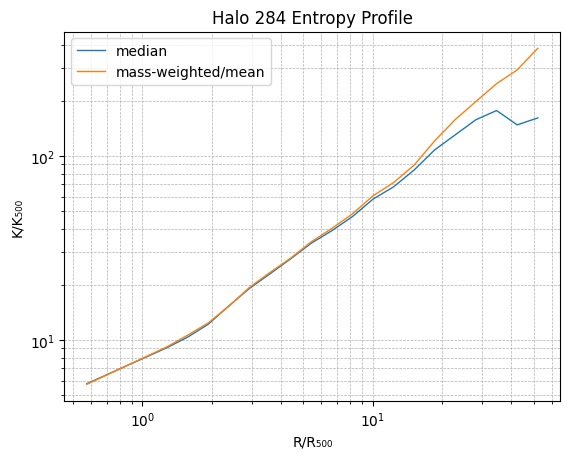

In [ ]:
normalized_r = radial_bin_centres/R500
normalized_k_median = np.array(entropy_profile_median)/K500.value    
normalized_k_mean = np.array(entropy_profile_mean)/K500.value   
rstring = "R500"
kstring = "K500"
SUB = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")

plt.title("Halo " + str(halo_id) + " Entropy Profile")
plt.plot(normalized_r, normalized_k_median, label='median', lw=1)
plt.plot(normalized_r, normalized_k_mean, label='mass-weighted/mean', lw=1)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('R/' + rstring.translate(SUB))
plt.ylabel('K/' + kstring.translate(SUB))
plt.legend()

# Saving with dill

In [ ]:
def save_object_with_dill(obj, filename):
    with open(filename, 'wb') as f:  # Overwrites any existing file.
        dill.dump(obj, f, dill.HIGHEST_PROTOCOL)


save_object_with_dill(final_prod, output)
print("saved as "+ output_filename + " in " + output_path)


NameError: name 'final_prod' is not defined